In [21]:
import numpy as np
import pandas as pd 
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
data_path = "C:/Users/HP/Desktop/Superstore Sales Data Analysis Project/archive/train.csv"
superstore_df = pd.read_csv(os.path.join(data_path))

# Loading the Data

In [23]:
data_path = "C:/Users/HP/Desktop/Superstore Sales Data Analysis Project/archive/train.csv"
superstore_df = pd.read_csv(os.path.join(data_path))

In [24]:
missing_values = (superstore_df.isnull()).sum()
empty_strings = (superstore_df == '').sum()
zero_values = (superstore_df == 0).sum()
total_missing = missing_values + empty_strings + zero_values

missing_summary = pd.DataFrame({
    'NaN/None Count': missing_values,
    'Empty String Count': empty_strings,
    'Zero values':zero_values,
    'Total Missing': total_missing,
    'Missing Percentage': ((total_missing / len(superstore_df)) * 100).round(3)
    })

missing_summary = missing_summary.sort_values('Total Missing', ascending=False)
print(missing_summary)

               NaN/None Count  Empty String Count  Zero values  Total Missing  \
Postal Code                11                   0            0             11   
Row ID                      0                   0            0              0   
Order ID                    0                   0            0              0   
Order Date                  0                   0            0              0   
Ship Mode                   0                   0            0              0   
Ship Date                   0                   0            0              0   
Customer Name               0                   0            0              0   
Segment                     0                   0            0              0   
Country                     0                   0            0              0   
Customer ID                 0                   0            0              0   
City                        0                   0            0              0   
State                       

In [6]:
superstore_df.head(2)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94


## Cleaning Data

In [25]:
# Convert both date columns — note the day/month format
superstore_df['Order Date'] = pd.to_datetime(superstore_df['Order Date'], format='%d/%m/%Y')
superstore_df['Ship Date']  = pd.to_datetime(superstore_df['Ship Date'],  format='%d/%m/%Y')

# Adding Shipping Delay column
superstore_df["Shipping Delay"] = (superstore_df["Ship Date"] - superstore_df["Order Date"]).dt.days
# Droping less used columns 
superstore_df = superstore_df.drop(columns=["Country", "Row ID"])  

# removing null data
superstore_df = superstore_df.dropna()

In [18]:
print(superstore_df["Sales"].describe())
print("Total revenue:", superstore_df["Sales"].sum())
print("Skewness:", superstore_df["Sales"].skew())

count     9789.000000
mean       230.116193
std        625.302079
min          0.444000
25%         17.248000
50%         54.384000
75%        210.392000
max      22638.480000
Name: Sales, dtype: float64
Total revenue: 2252607.4127
Skewness: 13.053630955201138


### Sales by Monthly / yearly trend

Yearly sales:
 Order Date
2015-01-01    479856.2081
2016-01-01    454315.9054
2017-01-01    597225.4900
2018-01-01    721209.8092
Freq: YS-JAN, Name: Sales, dtype: float64


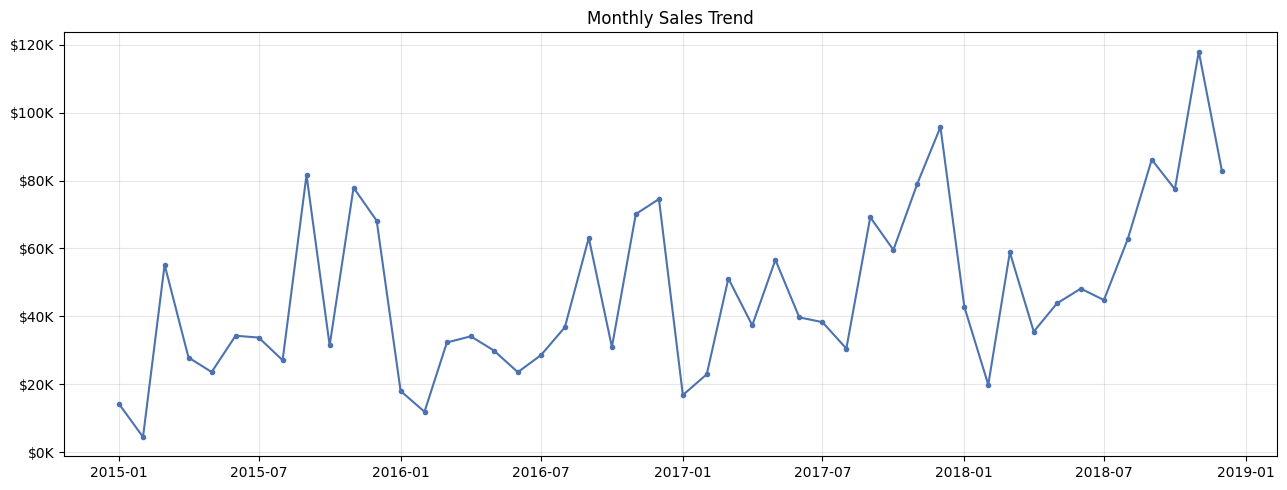

In [27]:
import matplotlib.ticker as mticker

monthly = superstore_df.set_index("Order Date").resample("MS")["Sales"].sum()
yearly = superstore_df.set_index("Order Date").resample("YS")["Sales"].sum()
print("Yearly sales:\n", yearly)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly.index, monthly.values, marker="o", markersize=3, color="#4C72B0")
ax.set_title("Monthly Sales Trend")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("monthly_trend.png", dpi=120, bbox_inches="tight")
plt.show()


### Sales by Product Name

In [37]:
print(superstore_df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False).head(10))
print('*'*100)
print(superstore_df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10))
print('*'*100)
print(superstore_df.groupby("Ship Mode").agg(orders=("Sales", "count"),
                                   avg_sale=("Sales", "mean"),
                                   avg_delay=("Shipping Delay", "mean")))

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64
****************************************************************************************************
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               

### Sales by Category / Sub-Category

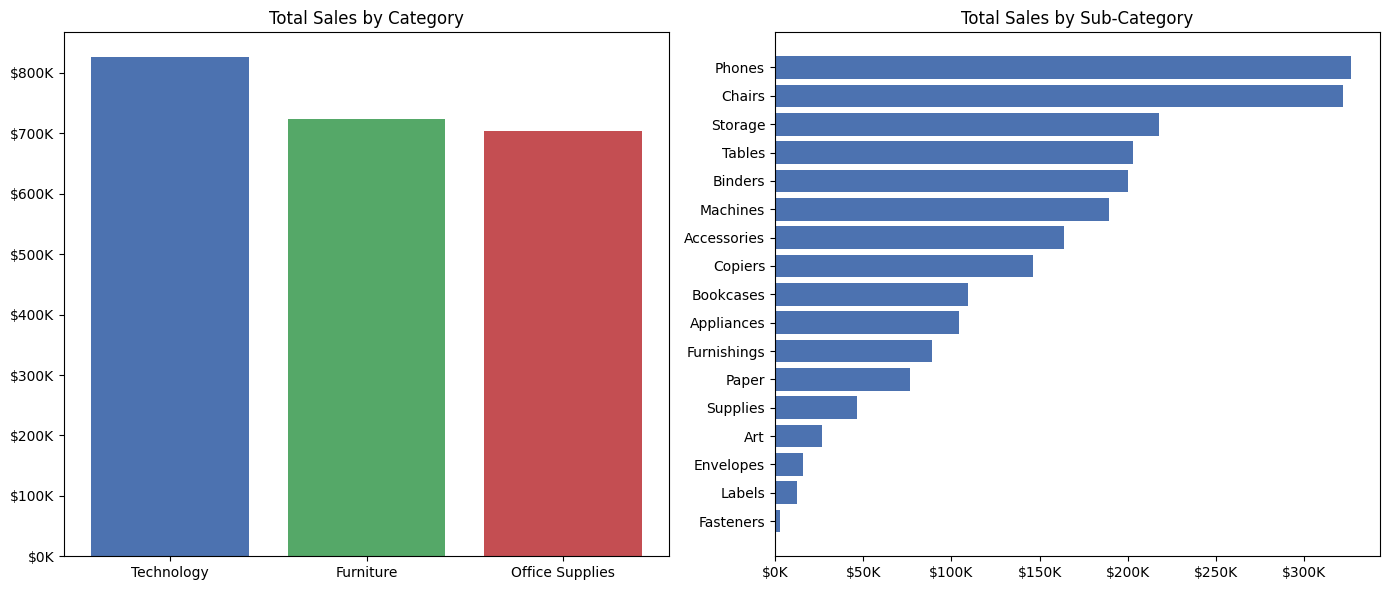

In [34]:
cat_sales = superstore_df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
subcat_sales = superstore_df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].bar(cat_sales.index, cat_sales.values, color=["#4C72B0", "#55A868", "#C44E52"])
axes[0].set_title("Total Sales by Category")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
subcat_sorted = subcat_sales.sort_values()
axes[1].barh(subcat_sorted.index, subcat_sorted.values, color="#4C72B0")
axes[1].set_title("Total Sales by Sub-Category")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
plt.tight_layout()
plt.savefig("sales_by_category.png", dpi=120, bbox_inches="tight")
plt.show()

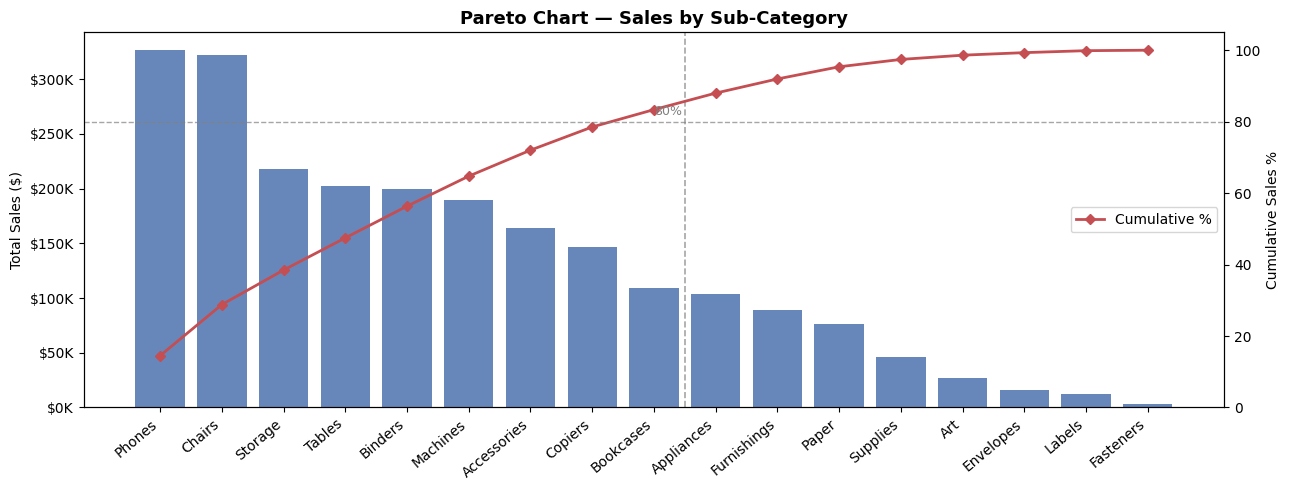

80% revenue sub-categories: ['Phones', 'Chairs', 'Storage', 'Tables', 'Binders', 'Machines', 'Accessories', 'Copiers', 'Bookcases']


In [31]:
subcat = superstore_df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)
cumulative_pct = subcat.cumsum() / subcat.sum() * 100
 
fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(subcat.index, subcat.values, color="#4C72B0", alpha=0.85)
ax1.set_ylabel("Total Sales ($)")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
ax1.set_title("Pareto Chart — Sales by Sub-Category", fontsize=13, fontweight="bold")
plt.xticks(rotation=40, ha="right")
 
ax2 = ax1.twinx()
ax2.plot(range(len(subcat)), cumulative_pct.values, color="#C44E52", marker="D",
         markersize=5, linewidth=2, label="Cumulative %")
ax2.axhline(80, color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax2.set_ylabel("Cumulative Sales %")
ax2.set_ylim(0, 105)
ax2.annotate("80%", xy=(0, 80), xytext=(8, 82), fontsize=9, color="gray")
ax2.legend(loc="center right")
 
cutoff_idx = (cumulative_pct >= 80).idxmax()
cutoff_pos = list(subcat.index).index(cutoff_idx)
ax1.axvline(cutoff_pos + 0.5, color="gray", linestyle="--", linewidth=1.2, alpha=0.7)
 
plt.tight_layout()
plt.savefig("p5_pareto.png", dpi=130, bbox_inches="tight")
plt.show()
print("80% revenue sub-categories:", list(subcat.index[:cutoff_pos + 1]))
 


### Sales by Region / Segment / State

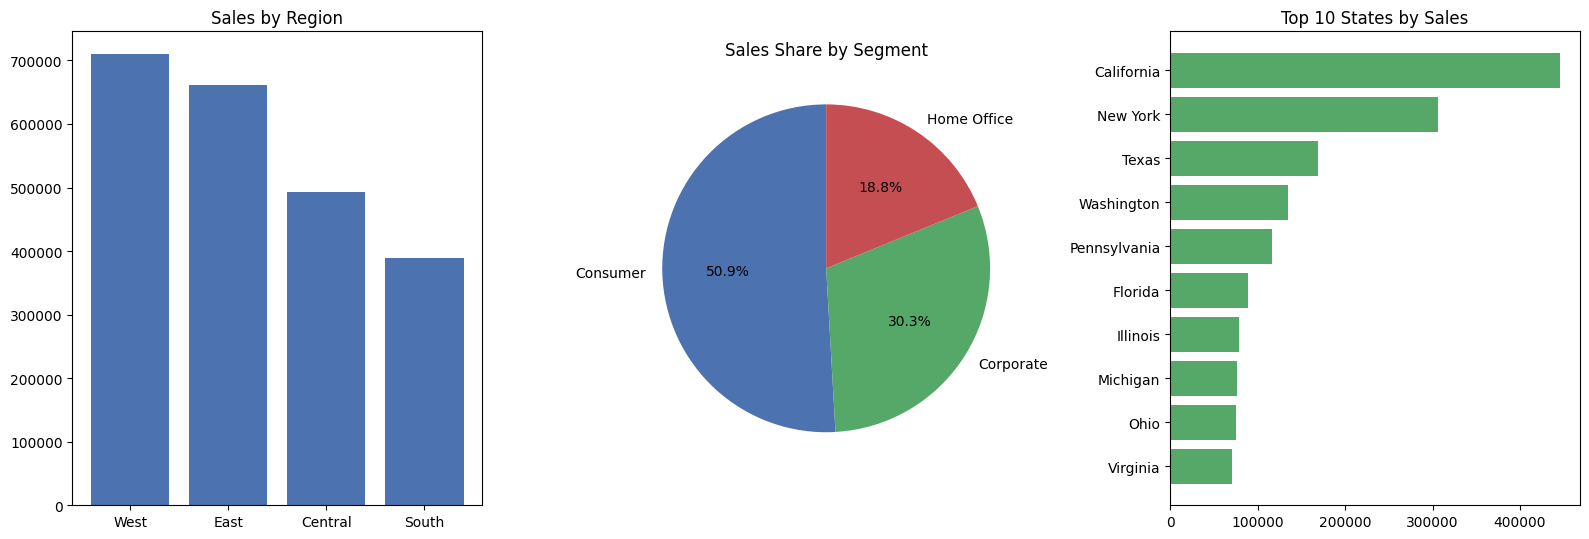

In [36]:
region_sales = superstore_df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
segment_sales = superstore_df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
top_states = superstore_df.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
axes[0].bar(region_sales.index, region_sales.values, color="#4C72B0")
axes[0].set_title("Sales by Region")
axes[1].pie(segment_sales.values, labels=segment_sales.index, autopct="%1.1f%%",
            colors=["#4C72B0", "#55A868", "#C44E52"], startangle=90)
axes[1].set_title("Sales Share by Segment")
ts = top_states.sort_values()
axes[2].barh(ts.index, ts.values, color="#55A868")
axes[2].set_title("Top 10 States by Sales")
plt.tight_layout()
plt.savefig("sales_geo_segment.png", dpi=120, bbox_inches="tight")
plt.show()

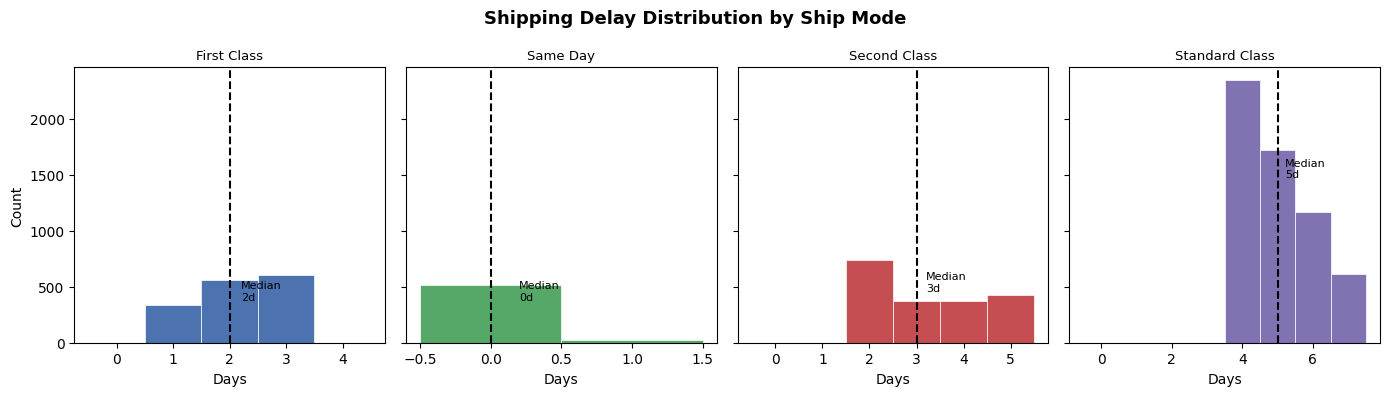

In [19]:
modes = sorted(superstore_df["Ship Mode"].unique())
mode_colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]
 
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
fig.suptitle("Shipping Delay Distribution by Ship Mode", fontsize=13, fontweight="bold")
 
for ax, mode, col in zip(axes, modes, mode_colors):
    data = superstore_df[superstore_df["Ship Mode"] == mode]["Shipping Delay"]
    ax.hist(data, bins=range(0, data.max() + 2), color=col, edgecolor="white",
            linewidth=0.5, align="left")
    ax.set_title(mode, fontsize=9.5)
    ax.set_xlabel("Days")
    median = data.median()
    ax.axvline(median, color="black", linestyle="--", linewidth=1.5)
    ax.annotate(f"Median\n{median:.0f}d", xy=(median, ax.get_ylim()[1] * 0.6),
                xytext=(median + 0.2, ax.get_ylim()[1] * 0.6), fontsize=8)
 
axes[0].set_ylabel("Count")
plt.tight_layout()
plt.savefig("p6_shipping.png", dpi=130, bbox_inches="tight")
plt.show()
 

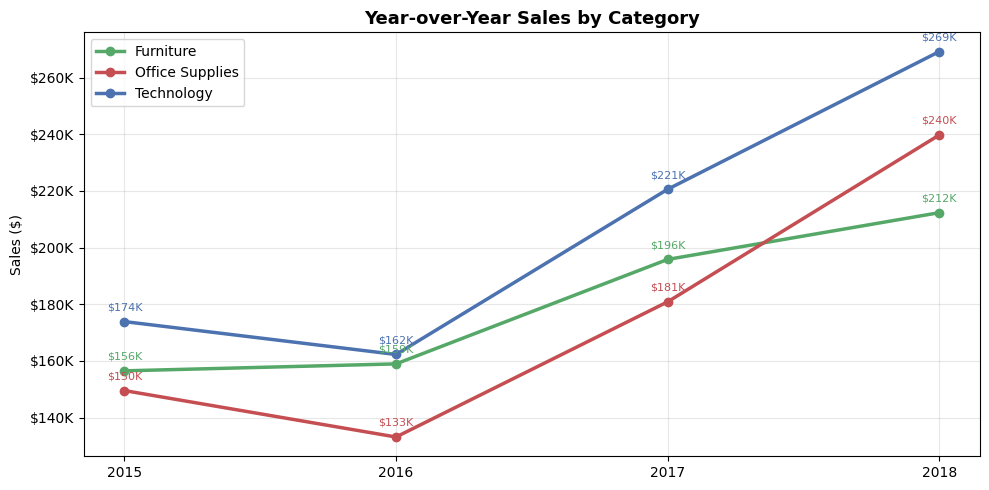

In [28]:
superstore_df["Year"] = superstore_df["Order Date"].dt.year
superstore_df["Month"] = superstore_df["Order Date"].dt.month
yoy = superstore_df.groupby(["Year", "Category"])["Sales"].sum().unstack()
 
fig, ax = plt.subplots(figsize=(10, 5))
cat_colors = {"Technology": "#4C72B0", "Furniture": "#55A868", "Office Supplies": "#C44E52"}
for cat in yoy.columns:
    ax.plot(yoy.index, yoy[cat], marker="o", label=cat, color=cat_colors[cat], linewidth=2.5)
    for yr, val in yoy[cat].items():
        ax.annotate(f"${val/1000:.0f}K", xy=(yr, val), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=8, color=cat_colors[cat])
 
ax.set_title("Year-over-Year Sales by Category", fontsize=13, fontweight="bold")
ax.set_ylabel("Sales ($)")
ax.set_xticks(yoy.index)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("p3_yoy_category.png", dpi=130, bbox_inches="tight")
plt.show()

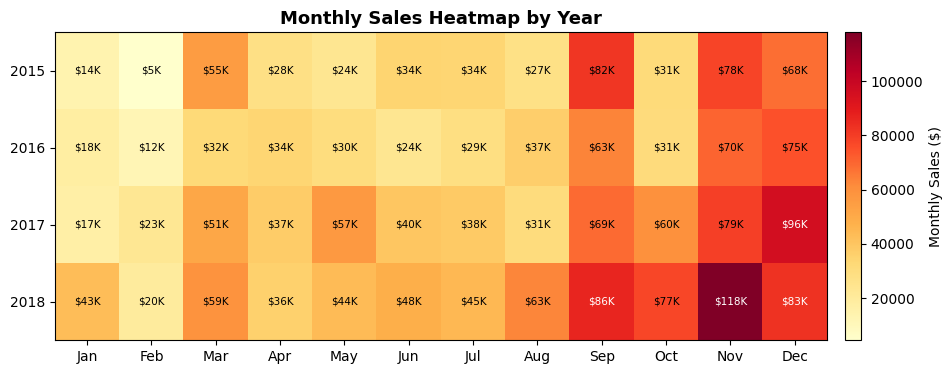

In [29]:
pivot = superstore_df.groupby(["Year", "Month"])["Sales"].sum().unstack()
 
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(12))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
plt.colorbar(im, ax=ax, label="Monthly Sales ($)", pad=0.02)
ax.set_title("Monthly Sales Heatmap by Year", fontsize=13, fontweight="bold")
 
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        ax.text(j, i, f"${val/1000:.0f}K", ha="center", va="center",
                fontsize=7.5, color="black" if val < pivot.values.max() * 0.7 else "white")
 

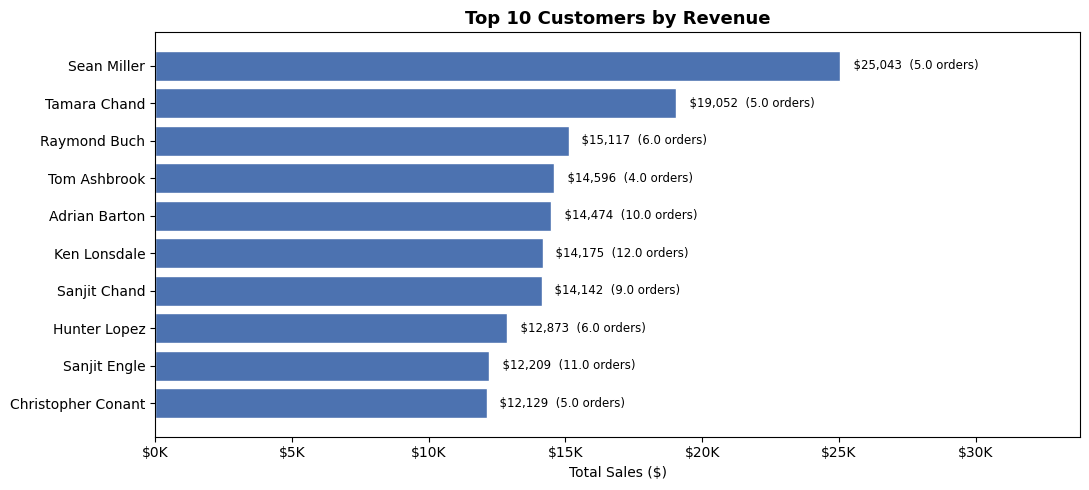

In [30]:
top_customers = (
    superstore_df.groupby("Customer Name")
    .agg(total_sales=("Sales", "sum"), order_count=("Order ID", "nunique"))
    .sort_values("total_sales", ascending=False)
    .head(10)
)
 
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top_customers.index[::-1], top_customers["total_sales"][::-1],
        color="#4C72B0", edgecolor="white")
ax.set_xlabel("Total Sales ($)")
ax.set_title("Top 10 Customers by Revenue", fontsize=13, fontweight="bold")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
 
for bar, (_, row) in zip(ax.patches, top_customers[::-1].iterrows()):
    ax.text(bar.get_width() + 200, bar.get_y() + bar.get_height() / 2,
            f"  ${row['total_sales']:,.0f}  ({row['order_count']} orders)",
            va="center", fontsize=8.5)
 
ax.set_xlim(0, top_customers["total_sales"].max() * 1.35)
plt.tight_layout()
plt.savefig("p7_top_customers.png", dpi=130, bbox_inches="tight")
plt.show()
 